In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
import sklearn

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/credit-screening/crx.data"

data = pd.read_csv(url, header=None)   # Tells pandas that the first row contains actual data, not column headings


In [3]:
data.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,b,30.83,0.000,u,g,w,v,1.25,t,t,1,f,g,00202,0,+
1,a,58.67,4.460,u,g,q,h,3.04,t,t,6,f,g,00043,560,+
2,a,24.50,0.500,u,g,q,h,1.50,t,f,0,f,g,00280,824,+
3,b,27.83,1.540,u,g,w,v,3.75,t,t,5,t,g,00100,3,+
4,b,20.17,5.625,u,g,w,v,1.71,t,f,0,f,s,00120,0,+


In [4]:
data.shape

(690, 16)

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 690 entries, 0 to 689
Data columns (total 16 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       690 non-null    str    
 1   1       690 non-null    str    
 2   2       690 non-null    float64
 3   3       690 non-null    str    
 4   4       690 non-null    str    
 5   5       690 non-null    str    
 6   6       690 non-null    str    
 7   7       690 non-null    float64
 8   8       690 non-null    str    
 9   9       690 non-null    str    
 10  10      690 non-null    int64  
 11  11      690 non-null    str    
 12  12      690 non-null    str    
 13  13      690 non-null    str    
 14  14      690 non-null    int64  
 15  15      690 non-null    str    
dtypes: float64(2), int64(2), str(12)
memory usage: 86.4 KB


In [6]:
data.isnull().sum()


0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
dtype: int64

In [7]:
(data == "?").sum()   # checks every cell to see whether its value is ?

0     12
1     12
2      0
3      6
4      6
5      9
6      9
7      0
8      0
9      0
10     0
11     0
12     0
13    13
14     0
15     0
dtype: int64

In [8]:
for col in data.columns:       # iterates through every column
    if (data[col] == "?").any():   # checks whether a column contains at least one question mark
        print(f"Column {col}: {data[col].unique()}")   # displays the distinct values in that column

Column 0: <StringArray>
['b', 'a', '?']
Length: 3, dtype: str
Column 1: <StringArray>
['30.83', '58.67', '24.50', '27.83', '20.17', '32.08', '33.17', '22.92',
 '54.42', '42.50',
 ...
 '38.75', '35.58', '31.58', '15.75', '17.92', '30.33', '47.17', '25.83',
 '50.25', '36.42']
Length: 350, dtype: str
Column 3: <StringArray>
['u', 'y', '?', 'l']
Length: 4, dtype: str
Column 4: <StringArray>
['g', 'p', '?', 'gg']
Length: 4, dtype: str
Column 5: <StringArray>
['w', 'q', 'm', 'r', 'cc', 'k', 'c', 'd', 'x', 'i', 'e', 'aa', 'ff', 'j', '?']
Length: 15, dtype: str
Column 6: <StringArray>
['v', 'h', 'bb', 'ff', 'j', 'z', '?', 'o', 'dd', 'n']
Length: 10, dtype: str
Column 13: <StringArray>
['00202', '00043', '00280', '00100', '00120', '00360', '00164', '00080',
 '00180', '00052',
 ...
 '00303', '00349', '00224', '00369', '00076', '00231', '00309', '00416',
 '00465', '00256']
Length: 171, dtype: str


In [9]:
data = data.replace('?', np.nan)   # replaces every ? with Numpy's standard missing-value marker, np.nan
data.isnull().sum()           # counts the missing values in each column

0     12
1     12
2      0
3      6
4      6
5      9
6      9
7      0
8      0
9      0
10     0
11     0
12     0
13    13
14     0
15     0
dtype: int64

In [10]:
data.isnull().any(axis=1).sum()    # isnull() identifies missing cells, any(axis=1) checks whether each row has at least one missing values, sum() conts the rows where that condition is true

np.int64(37)

In [11]:
data.describe()     # generates statistical summaries of numerical columns

,2,7,10,14
count,690.000000,690.000000,690.00000,690.000000
mean,4.758725,2.223406,2.40000,1017.385507
std,4.978163,3.346513,4.86294,5210.102598
min,0.000000,0.000000,0.00000,0.000000
25%,1.000000,0.165000,0.00000,0.000000
50%,2.750000,1.000000,0.00000,5.000000
75%,7.207500,2.625000,3.00000,395.500000
max,28.000000,28.500000,67.00000,100000.000000


In [12]:
data[14].sort_values(ascending=False).head(10)  # data[14] selects column 14, sort_values arranges its values, ascending =false sorts from largest to smallest, head(10) displays the ten largest values

317    100000
132     51100
65      50000
6       31285
243     26726
245     18027
67      15108
180     15000
584     13212
117     11202
Name: 14, dtype: int64

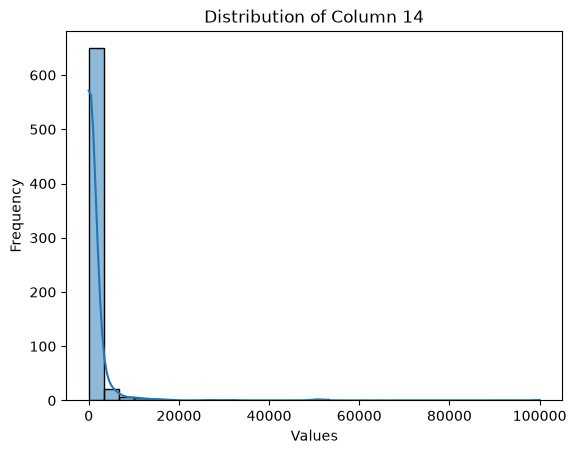

In [13]:
sns.histplot(data[14], bins=30, kde=True)  # sns.histplot() creates a histogram, data[14] selects the column, bins=30 divides the value into 30 intervals kde=True adds a smooth distribution curve
plt.title("Distribution of Column 14")  # Gives the chart a title
plt.xlabel("Values") # label the axis
plt.ylabel("Frequency")  # label the axis
plt.show()  # displays the chart


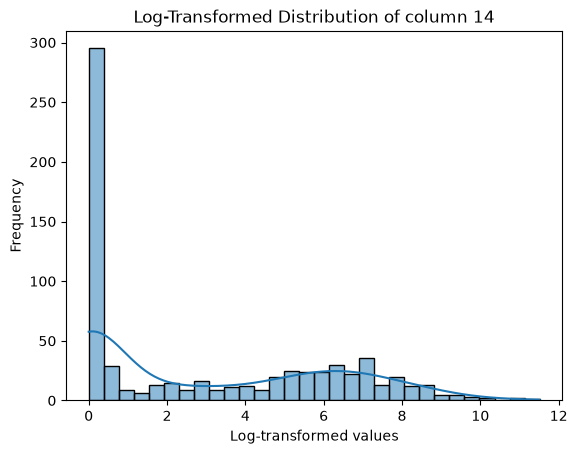

In [14]:
sns.histplot(np.log1p(data[14]), bins= 30, kde=True)
plt.title("Log-Transformed Distribution of column 14")
plt.xlabel("Log-transformed values")
plt.ylabel("Frequency")
plt.show()

In [15]:
data[[2,7,10,14]].skew()  # Measure Numerical skewness

2      1.488813
7      2.891330
10     5.152520
14    13.140655
dtype: float64

In [16]:
data[1] = pd.to_numeric(data[1])     # pd.to_numeric converts numerical strings into actual numbers
data[13] = pd.to_numeric(data[13])
data[[1, 2, 7, 10, 13, 14]].skew()


1      1.145892
2      1.488813
7      2.891330
10     5.152520
13     2.723993
14    13.140655
dtype: float64

In [17]:
data[15].value_counts()

15
-    383
+    307
Name: count, dtype: int64

In [18]:
data[15].value_counts(normalize=True) * 100     # normalize=True converts the counts into proportions. Multiplying by 100 converts them into percentages

15
-    55.507246
+    44.492754
Name: proportion, dtype: float64

In [19]:
# categorical feature analysis
data[0].value_counts()  # Tells how frequently each category appears

0
b    468
a    210
Name: count, dtype: int64

In [20]:
data[3].value_counts()

3
u    519
y    163
l      2
Name: count, dtype: int64

In [21]:
data[4].value_counts()

4
g     519
p     163
gg      2
Name: count, dtype: int64

In [22]:
data[5].value_counts()

5
c     137
q      78
w      64
i      59
aa     54
ff     53
k      51
cc     41
m      38
x      38
d      30
e      25
j      10
r       3
Name: count, dtype: int64

In [23]:
data[6].value_counts()

6
v     399
h     138
bb     59
ff     57
j       8
z       8
dd      6
n       4
o       2
Name: count, dtype: int64

In [24]:
data[8].value_counts()

8
t    361
f    329
Name: count, dtype: int64

In [25]:
data[9].value_counts()

9
f    395
t    295
Name: count, dtype: int64

In [26]:
data[11].value_counts()

11
f    374
t    316
Name: count, dtype: int64

In [27]:
data[12].value_counts()

12
g    625
s     57
p      8
Name: count, dtype: int64

In [28]:
data[13].describe()

count     677.000000
mean      184.014771
std       173.806768
min         0.000000
25%        75.000000
50%       160.000000
75%       276.000000
max      2000.000000
Name: 13, dtype: float64

In [29]:
data[13].skew()

np.float64(2.7239928852062745)

In [30]:
pd.crosstab(data[15], pd.cut(data[2], bins=5)) # To examine how numerical feature values relate to the target variable

2,"(-0.028, 5.6]","(5.6, 11.2]","(11.2, 16.8]","(16.8, 22.4]","(22.4, 28.0]"
15,,,,,
+,178,77,40,9,3
-,298,50,30,3,2


In [31]:
pd.crosstab(data[15], pd.cut(data[1], bins=5))  # To compare target class distribution across different ranges of column 1.

1,"(13.684, 27.05]","(27.05, 40.35]","(40.35, 53.65]","(53.65, 66.95]","(66.95, 80.25]"
15,,,,,
+,122,99,54,25,5
-,183,135,42,9,4


In [32]:
# Separate input features from the target variable.
X = data.drop(columns=[15])
y = data[15]

In [33]:
import numpy
import scipy
import sklearn

print("NumPy:", numpy.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)

NumPy: 2.5.0
SciPy: 1.18.1
Scikit-learn: 1.9.1


In [34]:
from sklearn.ensemble import RandomForestClassifier

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

In [36]:
# Identify numerical and categorical columns.
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

# Handle missing numerical values.
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Handle missing categorical values and convert categories to numbers.
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines.
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
# Build the complete machine learning pipeline.
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=100, random_state=42))
])

# Train the model using the training data.
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['+','-']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `tra

In [37]:
# Evaluating model accuracy
from sklearn.metrics import accuracy_score

# Generate predictions on unseen test data.
y_pred = model.predict(X_test)

# Calculate prediction accuracy.
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 85.5072463768116 %


In [38]:
from sklearn.metrics import classification_report, confusion_matrix

# Evaluate performance for each target class.
print(classification_report(y_test, y_pred))

# Display the confusion matrix.
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           +       0.82      0.87      0.84        61
           -       0.89      0.84      0.87        77

    accuracy                           0.86       138
   macro avg       0.85      0.86      0.85       138
weighted avg       0.86      0.86      0.86       138

Confusion Matrix:
[[53  8]
 [12 65]]


In [39]:
# Feature importance
# Identify the features that contributed most to predictions.
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

importances = model.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance", ascending=False
)

print(importance_df.head(10))

      Feature  Importance
37  cat__x8_f    0.210827
38  cat__x8_t    0.144605
3    num__x10    0.065811
0     num__x1    0.064739
1     num__x2    0.064361
2     num__x7    0.064029
5    num__x14    0.057934
4    num__x13    0.050200
39  cat__x9_f    0.044753
40  cat__x9_t    0.037680


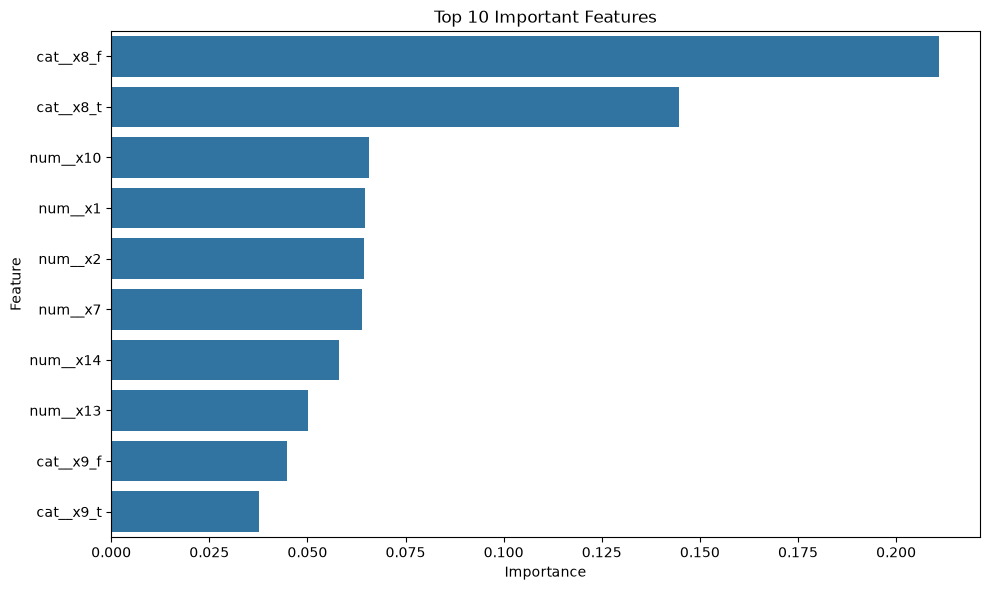

In [40]:
# Visualizing feature importance

# Visualize the ten most important features.
top_features = importance_df.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_features, x="Importance", y="Feature")

plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [41]:
# Validating model reliability
from sklearn.model_selection import cross_val_score

# Evaluate model consistency using 5-fold cross-validation.
scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")

print("Individual scores:", scores)
print("Average accuracy:", scores.mean() * 100, "%")

Individual scores: [0.85585586 0.90990991 0.85454545 0.9        0.85454545]
Average accuracy: 87.49713349713349 %


In [43]:
# Saving the trained model
import joblib

# Save the trained model and preprocessing pipeline.
joblib.dump(model, "credit_scoring_model.pkl")

['credit_scoring_model.pkl']

In [ ]:

# Making a prediction using one unseen test record.
sample = X_test.iloc[[0]]

prediction = model.predict(sample)

print("Predicted class:", prediction[0])
print("Actual class:", y_test.iloc[0])

Predicted class: -
Actual class: -
